# 01 — Đọc nhãn

Đọc ánh xạ lớp trong `data.yaml`, đếm các nhãn thuộc sáu mệnh giá mục tiêu và lưu kiểm kê để dùng ở bước 02. Cuối notebook có bốn ảnh mẫu với đường bao nhãn gốc.

In [1]:
from pathlib import Path
import re
import yaml

cwd = Path.cwd().resolve()
root = cwd if (cwd / "DATA_RAW").is_dir() else cwd.parents[1]
data_raw = root / "DATA_RAW"
dataset_roots = {
    "banknotes_v2": data_raw / "banknotes_v2" / "Banknotes-Recognition-main" / "Dataset_2",
    "money_v1": data_raw / "money_v1",
    "blindtrix_v1": data_raw / "blindtrix_v1",
    "currency_v6": data_raw / "currency_v6",
}
denominations = ["10000", "20000", "50000", "100000", "200000", "500000"]
name_to_denomination = {
    "10000": "10000", "10000vnd": "10000", "10k": "10000",
    "20000": "20000", "20000vnd": "20000", "20k": "20000",
    "50000": "50000", "50000vnd": "50000", "50k": "50000",
    "100000": "100000", "100000vnd": "100000", "100k": "100000",
    "200000": "200000", "200000vnd": "200000", "200k": "200000",
    "500000": "500000", "500000vnd": "500000", "500k": "500000",
}
class_maps = {}
yaml_paths = {}
for dataset_id, dataset_root in dataset_roots.items():
    yaml_path = dataset_root / "data.yaml"
    data = yaml.safe_load(yaml_path.read_text(encoding="utf-8"))
    yaml_paths[dataset_id] = yaml_path
    class_maps[dataset_id] = {}
    for class_id, class_name in enumerate(data["names"]):
        normalized_name = re.sub(r"[^a-z0-9]", "", str(class_name).lower())
        denomination = name_to_denomination.get(normalized_name)
        if denomination is not None:
            class_maps[dataset_id][class_id] = (str(class_name), denomination)


In [2]:
import csv
import pandas as pd
from IPython.display import display

rows = []
counts = {dataset_id: {denomination: 0 for denomination in denominations} for dataset_id in dataset_roots}
samples = {}
missing_labels = []
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for dataset_id, dataset_root in dataset_roots.items():
    for split in ["train", "valid", "test"]:
        image_folder = dataset_root / split / "images"
        label_folder = dataset_root / split / "labels"
        for image_path in sorted(image_folder.iterdir()):
            if not image_path.is_file() or image_path.suffix.lower() not in image_extensions:
                continue
            label_path = label_folder / f"{image_path.stem}.txt"
            if not label_path.is_file():
                missing_labels.append(str(image_path))
                continue
            image_rel_path = image_path.relative_to(data_raw).as_posix()
            label_rel_path = label_path.relative_to(data_raw).as_posix()
            source_rel_path = image_path.relative_to(data_raw / dataset_id).as_posix()
            for annotation_raw in label_path.read_text(encoding="utf-8").splitlines():
                if not annotation_raw.strip():
                    continue
                parts = annotation_raw.split()
                class_id = int(parts[0])
                class_info = class_maps[dataset_id].get(class_id)
                if class_info is None:
                    continue
                class_name, denomination = class_info
                counts[dataset_id][denomination] += 1
                rows.append({
                    "dataset_id": dataset_id,
                    "raw_split": split,
                    "image_path": image_rel_path,
                    "label_path": label_rel_path,
                    "source_rel_path": source_rel_path,
                    "class_id": class_id,
                    "class_name": class_name,
                    "denomination": denomination,
                    "annotation_raw": annotation_raw,
                })
                shape = "bbox" if len(parts) == 5 else "polygon"
                sample = (image_path, shape, list(map(float, parts[1:])))
                if dataset_id not in samples or (dataset_id == "currency_v6" and shape == "polygon" and samples[dataset_id][1] != "polygon"):
                    samples[dataset_id] = sample

inventory_path = data_raw / "metadata" / "raw_images.csv"
inventory_path.parent.mkdir(parents=True, exist_ok=True)
columns = ["dataset_id", "raw_split", "image_path", "label_path", "source_rel_path", "class_id", "class_name", "denomination", "annotation_raw"]
with inventory_path.open("w", newline="", encoding="utf-8-sig") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(rows)

count_table = pd.DataFrame.from_dict(counts, orient="index", columns=denominations)
count_table.index.name = "source"
display(count_table)
if missing_labels:
    print("Ảnh không có tệp nhãn:", len(missing_labels), missing_labels[:10])


,10000,20000,50000,100000,200000,500000
source,,,,,,
banknotes_v2,436,227,239,471,359,365
money_v1,1237,1036,1021,1222,1664,1108
blindtrix_v1,893,880,717,678,881,879
currency_v6,329,235,87,44,247,356


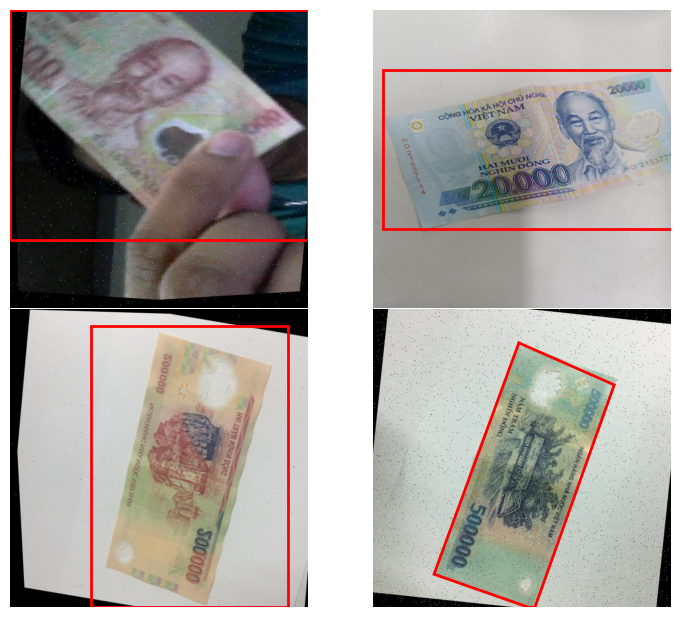

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Rectangle

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, dataset_id in zip(axes.flat, dataset_roots):
    image_path, shape, coords = samples[dataset_id]
    with Image.open(image_path) as source_image:
        image = source_image.convert("RGB")
    ax.imshow(image)
    if shape == "bbox":
        x_center, y_center, width, height = coords
        ax.add_patch(Rectangle(((x_center - width / 2) * image.width, (y_center - height / 2) * image.height), width * image.width, height * image.height, fill=False, edgecolor="red", linewidth=2))
    else:
        points = [(coords[index] * image.width, coords[index + 1] * image.height) for index in range(0, len(coords), 2)]
        ax.add_patch(Polygon(points, closed=True, fill=False, edgecolor="red", linewidth=2))
    ax.axis("off")
plt.tight_layout(pad=0.1)
plt.show()
